# 🚀 Модуль 2. Урок 4. Подзапросы и Common Table Expressions (CTE): читаемый модульный SQL

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_02_sql/lesson_04_subqueries_and_cte.ipynb)

## 📌 Бизнес-контекст и методология
Сложные аналитические пайплайны требуют многоэтапной обработки данных.
Вложенные подзапросы (Subqueries) создают «код-спагетти», который невозможно отлаживать и поддерживать.
Индустриальный стандарт современной аналитики (SQL Style Guide dbt/GitLab) предписывает использование **Common Table Expressions (CTE)** с конструкцией `WITH ... AS (...)`.
Это делает код модульным, самодокументируемым и легко переносимым в дашборды и dbt-модели.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

db_path = ensure_dataset("ecommerce.db")
conn = sqlite3.connect(db_path)
print(f"🟢 Подключение к базе данных успешно установлено: {db_path}")

🟢 Подключение к базе данных успешно установлено: course\datasets\ecommerce.db


## 🔍 Разбор механики и демонстрация на реальных данных
Построим промышленный 3-этапный CTE для RFM-сегментации клиентов:
1. `customer_spend`: агрегация совокупной выручки и частоты заказов
2. `customer_stats`: расчет квантилей и средних бенчмарков
3. `rfm_segmented`: присвоение бизнес-статуса (VIP, Regular, Low Value)

In [2]:
# Демонстрация: Модульный CTE для сегментации клиентов
query_cte = """
WITH customer_orders AS (
    SELECT 
        o.customer_id,
        COUNT(DISTINCT o.order_id) as total_orders,
        SUM(oi.total_amount) as monetary_value,
        MAX(o.order_date) as last_order_date
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.status = 'Completed'
    GROUP BY o.customer_id
),
customer_segments AS (
    SELECT 
        customer_id,
        total_orders,
        ROUND(monetary_value, 2) as monetary_value,
        ROUND(monetary_value / total_orders, 2) as aov,
        CASE 
            WHEN monetary_value >= 5000 AND total_orders >= 3 THEN '👑 VIP Champions'
            WHEN monetary_value >= 2500 THEN '💎 High Value'
            WHEN total_orders >= 2 THEN '🔄 Loyal Repeats'
            ELSE '🌱 One-time Entry'
        END as customer_tier
    FROM customer_orders
)
SELECT 
    customer_tier,
    COUNT(*) as customer_count,
    ROUND(SUM(monetary_value), 2) as total_tier_revenue,
    ROUND(AVG(aov), 2) as avg_tier_aov
FROM customer_segments
GROUP BY customer_tier
ORDER BY total_tier_revenue DESC;
"""
df_cte_summary = pd.read_sql_query(query_cte, conn)
display(df_cte_summary)

,customer_tier,customer_count,total_tier_revenue,avg_tier_aov
0,👑 VIP Champions,129,1041364.97,1543.53
1,💎 High Value,246,911545.34,1942.19
2,🌱 One-time Entry,393,412253.48,1048.99
3,🔄 Loyal Repeats,148,245195.82,772.67


## 📊 Визуализация бизнес-кейса: RFM-сегменты и вклад в совокупную выручку
Визуализируем правило Парето: какая доля клиентов генерирует основную прибыль бизнеса.

C:\Users\serge\AppData\Local\Temp\ipykernel_30304\1023175764.py:26: UserWarning: Glyph 128081 (\N{CROWN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\serge\AppData\Local\Temp\ipykernel_30304\1023175764.py:26: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\serge\AppData\Local\Temp\ipykernel_30304\1023175764.py:26: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\serge\AppData\Local\Temp\ipykernel_30304\1023175764.py:26: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\serge\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128081 (\N{CROWN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\serge\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\

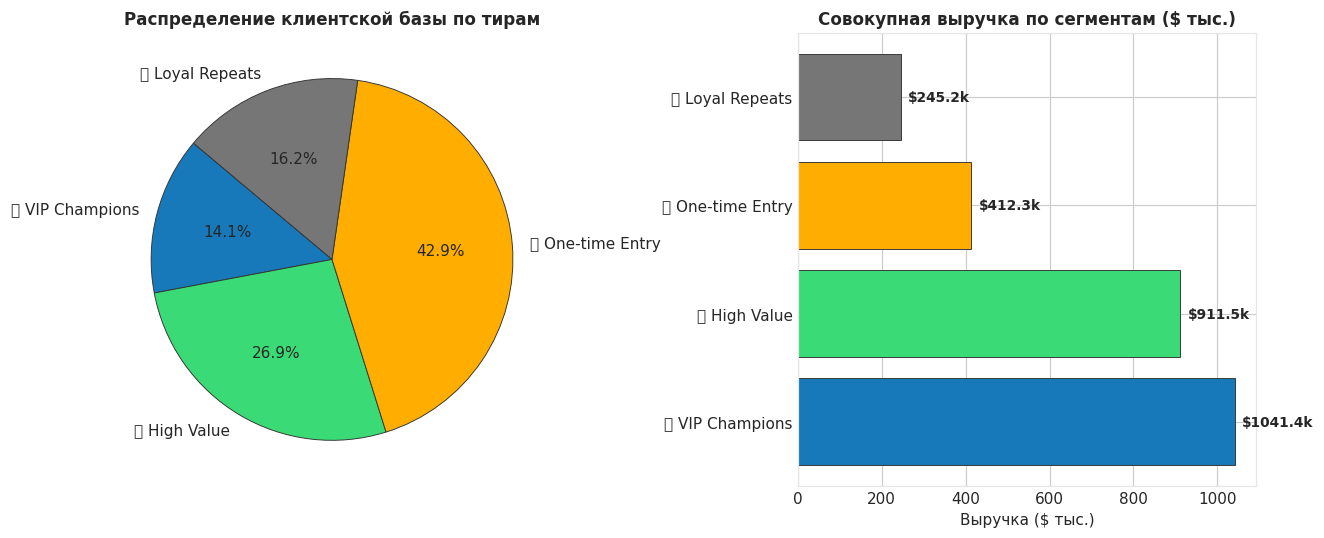

In [3]:
# Построение 2-панельного чарта: Клиенты vs Выручка по тирам
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=110)

palette = [PRIMARY, SUCCESS, WARNING, SECONDARY]

# Панель 1: Доля пользователей в сегментах
ax1.pie(df_cte_summary['customer_count'], 
        labels=df_cte_summary['customer_tier'], 
        autopct='%1.1f%%', 
        colors=palette, 
        startangle=140, 
        wedgeprops=dict(edgecolor='#333333', linewidth=0.6))
ax1.set_title("Распределение клиентской базы по тирам", fontsize=11, fontweight='bold')

# Панель 2: Сгенерированная выручка ($ тыс.)
bars = ax2.barh(df_cte_summary['customer_tier'], df_cte_summary['total_tier_revenue'] / 1000, 
                color=palette, edgecolor='#333333', linewidth=0.6)
ax2.set_title("Совокупная выручка по сегментам ($ тыс.)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Выручка ($ тыс.)")

for b in bars:
    w = b.get_width()
    ax2.annotate(f"${w:.1f}k", xy=(w, b.get_y() + b.get_height()/2), xytext=(5, 0),
                 textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: CTE для поиска первого и последнего заказа
Напишите модульный запрос с CTE, находящим дату первого (`first_order`) и последнего (`last_order`) заказа для каждого клиента со статусом `Completed`.

In [4]:
### ВАШ КОД ЗДЕСЬ
query_first_last = """
WITH client_bounds AS (
    SELECT 
        customer_id,
        MIN(order_date) as first_order,
        MAX(order_date) as last_order,
        COUNT(order_id) as total_completed_orders
    FROM orders
    WHERE status = 'Completed'
    GROUP BY customer_id
)
SELECT 
    customer_id,
    first_order,
    last_order,
    total_completed_orders
FROM client_bounds
WHERE total_completed_orders >= 2
ORDER BY total_completed_orders DESC
LIMIT 10;
"""

df_bounds = pd.read_sql_query(query_first_last, conn)
display(df_bounds.head(5))

assert not df_bounds.empty, "Результат не должен быть пустым"
assert (df_bounds['first_order'] <= df_bounds['last_order']).all(), "Дата первого заказа не может быть позже последнего"
print("✅ Тест успешно пройден: CTE отработал корректно и логично!")

,customer_id,first_order,last_order,total_completed_orders
0,24,2025-08-27 00:00:00,2026-02-16 00:00:00,11
1,377,2025-07-20 00:00:00,2026-04-06 00:00:00,11
2,869,2025-05-26 00:00:00,2026-02-01 00:00:00,11
3,1022,2025-09-09 00:00:00,2026-06-12 00:00:00,11
4,116,2026-04-09 00:00:00,2026-09-28 00:00:00,10


✅ Тест успешно пройден: CTE отработал корректно и логично!


### 💡 Рефакторинг SQL: правильное именование CTE
1. Используйте осмысленные существительные во множественном числе (`user_orders`, `monthly_aggregates`).
2. Ограничивайте размер CTE: фильтруйте строки и исключайте ненужные колонки на самом раннем этапе конвейера.